In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

print("1. Loading raw M5 data (First 100 products only for downsampling)...")
sales = pd.read_csv('../data/raw/sales_train_validation.csv', nrows=100)
calendar = pd.read_csv('../data/raw/calendar.csv')

print("2. Reshaping data from Wide to Long format...")
id_vars = ['id', 'item_id', 'dept_id', 'cat_id', 'store_id', 'state_id']
sales_long = pd.melt(sales, id_vars=id_vars, var_name='d', value_name='sales')

print("3. Merging with Calendar dates...")
sales_long = sales_long.merge(calendar[['d', 'date', 'wm_yr_wk', 'event_name_1', 'weekday']], on='d', how='left')
sales_long['date'] = pd.to_datetime(sales_long['date'])

print(f"Dataset ready! Total rows: {len(sales_long)}")
display(sales_long.head())

1. Loading raw M5 data (First 100 products only for downsampling)...
2. Reshaping data from Wide to Long format...
3. Merging with Calendar dates...
Dataset ready! Total rows: 191300


,id,item_id,dept_id,cat_id,store_id,state_id,d,sales,date,wm_yr_wk,event_name_1,weekday
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,NaN,Saturday
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,NaN,Saturday
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,NaN,Saturday
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,NaN,Saturday
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0,2011-01-29,11101,NaN,Saturday


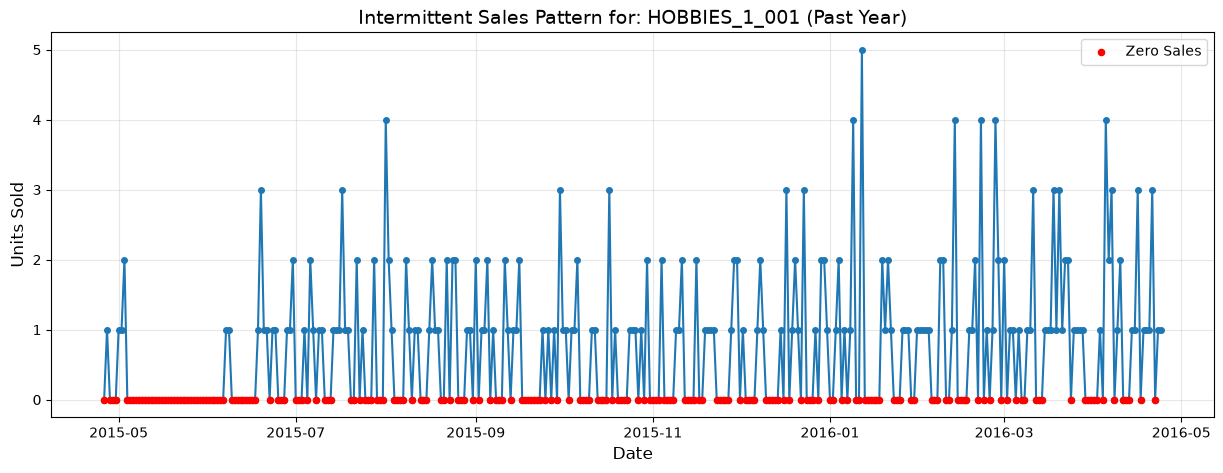

4. Saving processed dataset for ML training...
Saved to ml_pipeline/data/processed/downsampled_sales.csv


In [2]:
# Select the very first product in our dataset
sample_item = sales_long['item_id'].iloc[0]
sample_data = sales_long[sales_long['item_id'] == sample_item].sort_values('date')

# Plot the last 365 days of sales for this product
sample_data_recent = sample_data.tail(365)

plt.figure(figsize=(15, 5))
plt.plot(sample_data_recent['date'], sample_data_recent['sales'], 
         marker='o', linestyle='-', markersize=4, color='#1f77b4')
plt.title(f"Intermittent Sales Pattern for: {sample_item} (Past Year)", fontsize=14)
plt.ylabel("Units Sold", fontsize=12)
plt.xlabel("Date", fontsize=12)
plt.grid(True, alpha=0.3)

# Highlight zero-sale days in red to emphasize sparsity
zero_sales = sample_data_recent[sample_data_recent['sales'] == 0]
plt.scatter(zero_sales['date'], zero_sales['sales'], color='red', s=20, zorder=5, label='Zero Sales')
plt.legend()
plt.show()

print("4. Saving processed dataset for ML training...")
sales_long.to_csv('../data/processed/downsampled_sales.csv', index=False)
print("Saved to ml_pipeline/data/processed/downsampled_sales.csv")